**Task 1 — Project setup**

In [15]:
from pathlib import Path
import re
import warnings

import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay)

import joblib

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 140)

print("All imports completed successfully!")


All imports completed successfully!


**Task 2 — Load the dataset**

In [18]:
DATA_PATH = Path(r"C:/Users/HomePC/Downloads/Reviews.csv")
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found at: {DATA_PATH}\n"
        "Check the filename and folder location."
    )

reviews = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("Dataset shape:", reviews.shape)

display(reviews.head())


Dataset loaded successfully!
Dataset shape: (568454, 10)


,Id,ProductId,UserId,ProfileName,HelpfulnessNumerator,HelpfulnessDenominator,Score,Time,Summary,Text
0,1,B001E4KFG0,A3SGXH7AUHU8GW,delmartian,1,1,5,1303862400,Good Quality Dog Food,I have bought several of the Vitality canned dog food products and have found them all to be of good quality. The product looks more lik...
1,2,B00813GRG4,A1D87F6ZCVE5NK,dll pa,0,0,1,1346976000,Not as Advertised,Product arrived labeled as Jumbo Salted Peanuts...the peanuts were actually small sized unsalted. Not sure if this was an error or if th...
2,3,B000LQOCH0,ABXLMWJIXXAIN,"Natalia Corres ""Natalia Corres""",1,1,4,1219017600,"""Delight"" says it all","This is a confection that has been around a few centuries. It is a light, pillowy citrus gelatin with nuts - in this case Filberts. And..."
3,4,B000UA0QIQ,A395BORC6FGVXV,Karl,3,3,2,1307923200,Cough Medicine,If you are looking for the secret ingredient in Robitussin I believe I have found it. I got this in addition to the Root Beer Extract I...
4,5,B006K2ZZ7K,A1UQRSCLF8GW1T,"Michael D. Bigham ""M. Wassir""",0,0,5,1350777600,Great taffy,"Great taffy at a great price. There was a wide assortment of yummy taffy. Delivery was very quick. If your a taffy lover, this is a d..."


**Task 3 — Inspect the dataset**

In [23]:
print("Data shape (rows, columns):", reviews.shape)
print("\nColumn names:")
print(reviews.columns.to_list())
print("\nDataset information:")
reviews.info()


Data shape (rows, columns): (568454, 10)

Column names:
['Id', 'ProductId', 'UserId', 'ProfileName', 'HelpfulnessNumerator', 'HelpfulnessDenominator', 'Score', 'Time', 'Summary', 'Text']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 568454 entries, 0 to 568453
Data columns (total 10 columns):
 #   Column                  Non-Null Count   Dtype
---  ------                  --------------   -----
 0   Id                      568454 non-null  int64
 1   ProductId               568454 non-null  str  
 2   UserId                  568454 non-null  str  
 3   ProfileName             568428 non-null  str  
 4   HelpfulnessNumerator    568454 non-null  int64
 5   HelpfulnessDenominator  568454 non-null  int64
 6   Score                   568454 non-null  int64
 7   Time                    568454 non-null  int64
 8   Summary                 568427 non-null  str  
 9   Text                    568454 non-null  str  
dtypes: int64(5), str(5)
memory usage: 43.4 MB


**Task 4 — Data quality checks**

print("\nMissing values per column:")
missing_values = reviews.isna().sum().sort_values().to_frame("Missing_Values")
display(missing_values)
duplicate_rows = reviews.duplicated().sum()
print("\nExact duplicate_rows:", duplicate_rows)

if "Score" not in reviews.columns:
    raise ValueError("The dataset does not contain the required 'Score' column.")

print("\nStart rating distribution:")
display(
    reviews["Score"]
    .value_counts(dropna=False)
    .sort_index()
    .to_frame("reviews_counts")
)
print("\nUnique non-missing ratings:")
display(sorted(reviews["Score"].dropna().unique()))

**Task 5 — Define the modelling columns**

In [32]:
rating_col = "Score"
text_col = "Text"

required = {rating_col, text_col}
missing_columns = required - set(reviews.columns)

if missing_columns:
    raise ValueError(f"Required column missing from dataset: {missing_columns}")

print("Required columns are available.")

Required columns are available.


**Task 6 — Clean the review text**

In [36]:
def clean_review(text):
    if pd.isna(text):
        return ""
        
    text = str(text)
    text = re.sub(r"<[^>]+>", " ", text)
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"[^A-Za-z0-9\s.,!?'\-]", " ", text)
    text = re.sub(r"\s+", " ", text)
    
    return text.lower().strip()

test_examples = [
    "<p>This product is GREAT!</p>",
    "This product is not good. Visit https://example.com",
    "  Fresh coffee   tastes nice  "
]

for example in test_examples:
    print("Original:", example)
    print("Cleaned: ", clean_review(example))
    print()


Original: <p>This product is GREAT!</p>
Cleaned:  this product is great!

Original: This product is not good. Visit https://example.com
Cleaned:  this product is not good. visit

Original:   Fresh coffee   tastes nice  
Cleaned:  fresh coffee tastes nice



**Task 7 — Clean the dataset**

In [47]:
rows_before_cleaning = len(reviews)
reviews = reviews.dropna(subset=[rating_col, text_col]).copy()
reviews[rating_col] = pd.to_numeric(
    reviews[rating_col], errors="coerce"
)
reviews = reviews.dropna(subset=[rating_col]).copy()

reviews = reviews[
    reviews[rating_col].between(1, 5)
    & (reviews[rating_col] % 1 == 0)
].copy()

reviews[rating_col] = reviews[rating_col].astype(int)
reviews["review_text"] = reviews[text_col].astype(str).str.strip()
reviews = reviews[reviews["review_text"].ne("")].copy()
reviews["_duplicate_key"] = (
    reviews["review_text"].str.lower().str.strip()
)
reviews = reviews.drop_duplicates(subset="_duplicate_key", keep="first"
).copy()

reviews = reviews.drop(columns="_duplicate_key")

reviews["clean_text"] = reviews["review_text"].apply(clean_review)

reviews = reviews[reviews["clean_text"].ne("")]. copy()

print("Rows before cleaning:", rows_before_cleaning)
print("Rows after cleaning:", len(reviews))
print("Rows removed:", rows_before_cleaning - len(reviews))
display(reviews[["Score", "review_text", "clean_text"]].head())

Rows before cleaning: 393568
Rows after cleaning: 393568
Rows removed: 0


,Score,review_text,clean_text
0,5,I have bought several of the Vitality canned dog food products and have found them all to be of good quality. The product looks more lik...,i have bought several of the vitality canned dog food products and have found them all to be of good quality. the product looks more lik...
1,1,Product arrived labeled as Jumbo Salted Peanuts...the peanuts were actually small sized unsalted. Not sure if this was an error or if th...,product arrived labeled as jumbo salted peanuts...the peanuts were actually small sized unsalted. not sure if this was an error or if th...
2,4,"This is a confection that has been around a few centuries. It is a light, pillowy citrus gelatin with nuts - in this case Filberts. And...","this is a confection that has been around a few centuries. it is a light, pillowy citrus gelatin with nuts - in this case filberts. and ..."
3,2,If you are looking for the secret ingredient in Robitussin I believe I have found it. I got this in addition to the Root Beer Extract I...,if you are looking for the secret ingredient in robitussin i believe i have found it. i got this in addition to the root beer extract i ...
4,5,"Great taffy at a great price. There was a wide assortment of yummy taffy. Delivery was very quick. If your a taffy lover, this is a d...","great taffy at a great price. there was a wide assortment of yummy taffy. delivery was very quick. if your a taffy lover, this is a deal."


**Task 8 — Create sentiment labels**

In [50]:
def rating_to_sentiment(score):
    if score in [1, 2]:
        return "Negative"
    elif score == 3:
        return "Neutral"
    elif score in [4, 5]:
        return "Positive"
    else:
        raise ValueError("Unexpected rating: {score}")
reviews["sentiment"] = reviews[rating_col].apply(rating_to_sentiment)
print("sentiment class counts:")
display(
    reviews["sentiment"]
    .value_counts()
    .reindex(["Negative", "Neutral", "Positive"], fill_value=0)
    .to_frame("review count")
)

    
    

sentiment class counts:


,review count
sentiment,
Negative,57065
Neutral,29752
Positive,306751


**Task 9 — Visualise sentiment distribution**

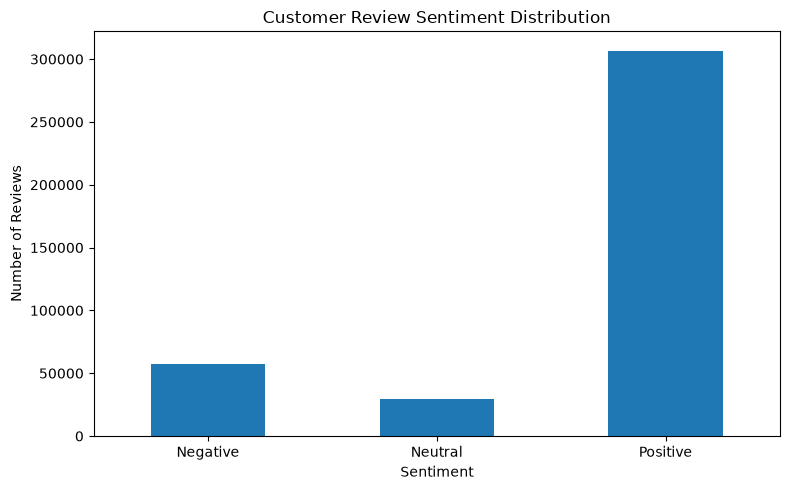

Positive reviews are the largest group, representing 77.94% of the cleaned dataset.


In [54]:
sentiment_order = ["Negative", "Neutral", "Positive"]
sentiment_counts = (
    reviews["sentiment"]
    .value_counts()
    .reindex(sentiment_order, fill_value=0)
)

plt.figure(figsize=(8, 5))
sentiment_counts.plot(kind="bar")
plt.title("Customer Review Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

dominant_sentiment = sentiment_counts.idxmax()
dominant_percentage = sentiment_counts.max() / len(reviews) * 100

print(
    f"{dominant_sentiment} reviews are the largest group, "
    f"representing {dominant_percentage:.2f}% of the cleaned dataset."
)



**Task 10 — Explore ratings and review length**

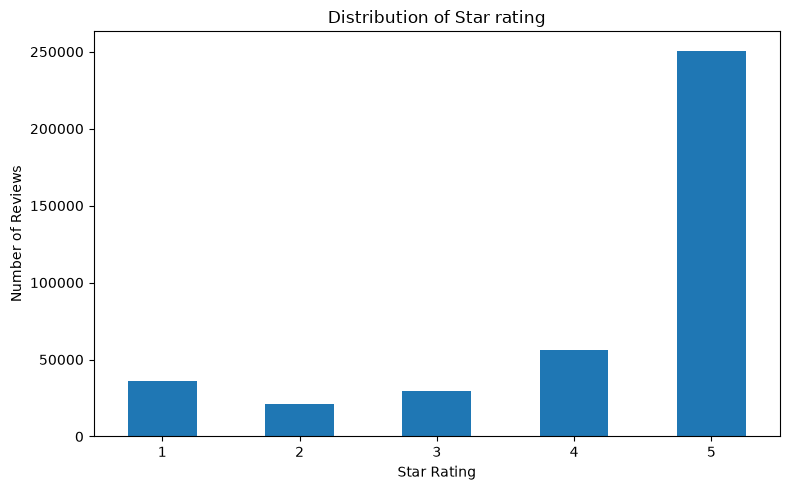

Mean and median length by sentiment


,mean,median,min,max
sentiment,,,,
Negative,85.25,63.0,3,2149
Neutral,96.16,70.0,7,3432
Positive,77.14,54.0,3,2520


<Figure size 800x500 with 0 Axes>

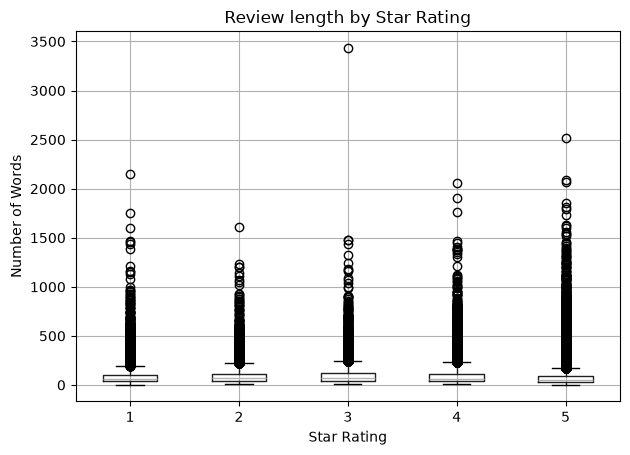

In [58]:
reviews["review_length"] = (
    reviews["review_text"].str.split().str.len()
)

rating_counts = reviews[rating_col].value_counts().sort_index()
plt.figure(figsize=(8, 5))
rating_counts.plot(kind="bar")
plt.title("Distribution of Star rating")
plt.xlabel("Star Rating")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
reviews.boxplot(column="review_length", by=rating_col)
plt.title("Review length by Star Rating")
plt.suptitle("")
plt.xlabel("Star Rating")
plt.ylabel("Number of Words")
plt.tight_layout()
plt.show

print("Mean and median length by sentiment")
display(
    reviews.groupby("sentiment")["review_length"]
    .agg(["mean", "median", "min", "max"])
    .round(2)
)
        


**Task 11 — Split the data into training and test sets**

In [60]:
x = reviews["clean_text"]
y = reviews["sentiment"]

x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
print("Training samples:", len(x_train))
print("Test samples:", len(x_test))

print("\nTest sentiment distribution:")
print(y_test.value_counts(normalize=True).mul(100).round(2))

Training samples: 314854
Test samples: 78714

Test sentiment distribution:
sentiment
Positive    77.94
Negative    14.50
Neutral      7.56
Name: proportion, dtype: float64


**Task 12 — Build the TF-IDF and Logistic Regression pipeline**

In [66]:
model = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=5000,
        ngram_range=(1, 2),
        min_df=2,
        max_df=0.98,
        sublinear_tf=True
    )),
     ("classifier", LogisticRegression(
         max_iter=1000,
         class_weight="balanced",
         random_state=42
    ))
])
model.fit(x_train, y_train)

print("TF-IDF + Logistic Regression pipelines trained successfully.")

print(
    "Number of TF-IDF features:",
    len(model.named_steps["tfidf"].get_feature_names_out())
)

TF-IDF + Logistic Regression pipelines trained successfully.
Number of TF-IDF features: 5000


**Task 13 — Generate test predictions**

In [70]:
y_pred = model.predict(x_test)
comparison = pd.DataFrame({
    "review_text": reviews.loc[x_test.index, "review_text"],
    "actual_sentiment": y_test,
    "predicted_sentiment": y_pred
},index=x_test.index)

print(comparison.head(10))

                                                                                                                                        review_text  \
400331  I got the machine for my birthday a few months ago and the only coffee I drank with it was starbucks. I was sort of disappointed, the co...   
517797  This tea can be mixed with milk powder and stevia or can be sweetened just with honey or stevia. I like it both ways but the cranberries...   
28823   This gluten-free bar is much better than most - a rich combination of just what it says - fruit and nuts.  However, the unit description...   
366025  I love these things - whenever I'm in NYC, I make a point of going to the one store I know that sells them and buying 5-6 packs for $1 a...   
176935              These are mildly flavored, have nori, and are larger than the usual rice snacks.  The flavor is similar to other rice crackers.   
41148   Black cherry is one of my favorite flavors and scents.  I love tea, so put the two tog

**Task 14 — Evaluate the model**

In [71]:
accuracy = accuracy_score(y_test, y_pred)
macro_precision = precision_score(
    y_test, y_pred, average="macro", zero_division=0
)
macro_recall = recall_score(
    y_test, y_pred, average="macro", zero_division=0
)
macro_f1 = f1_score(
    y_test, y_pred, average="macro", zero_division=0
)

print(f"Accuracy:         {accuracy:.4f}")
print(f"Macro Precision:  {macro_precision:.4f}")
print(f"Macro Recall:     {macro_recall:.4f}")
print(f"Macro F1-score:   {macro_f1:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    labels=["Negative", "Neutral", "Positive"],
    zero_division=0
))


Accuracy:         0.8023
Macro Precision:  0.6380
Macro Recall:     0.7325
Macro F1-score:   0.6596

Classification Report:
              precision    recall  f1-score   support

    Negative       0.67      0.73      0.70     11413
     Neutral       0.28      0.63      0.38      5950
    Positive       0.97      0.83      0.90     61351

    accuracy                           0.80     78714
   macro avg       0.64      0.73      0.66     78714
weighted avg       0.87      0.80      0.83     78714



**Task 15 — Display and interpret the confusion matrix**

,Predicted Negative,Predicted Neutral,Predicted Positive
Actual Negative,8373,2411,629
Actual Neutral,1334,3761,855
Actual Positive,2847,7482,51022


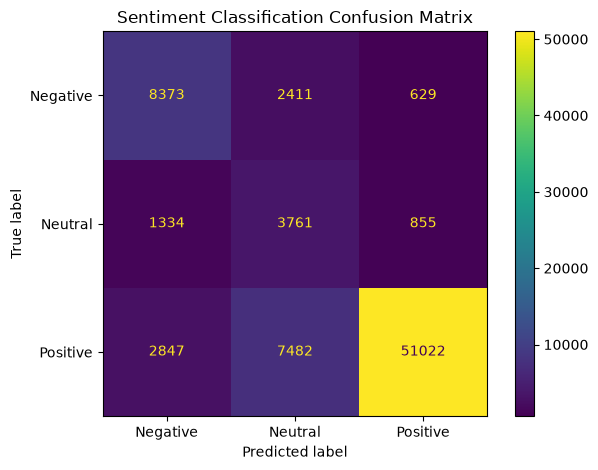

Largest class-to-class error: actual Positive predicted as Neutral (7482 reviews).


In [72]:
labels = ["Negative", "Neutral", "Positive"]

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=labels
)

display(pd.DataFrame(
    cm,
    index=[f"Actual {label}" for label in labels],
    columns=[f"Predicted {label}" for label in labels]
))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels
)

disp.plot(values_format="d")
plt.title("Sentiment Classification Confusion Matrix")
plt.tight_layout()
plt.show()

# Identify the largest off-diagonal error.
cm_errors = cm.copy()
np.fill_diagonal(cm_errors, 0)

if cm_errors.max() > 0:
    row_idx, col_idx = np.unravel_index(
        np.argmax(cm_errors), cm_errors.shape
    )
    print(
        f"Largest class-to-class error: actual {labels[row_idx]} "
        f"predicted as {labels[col_idx]} "
        f"({cm_errors[row_idx, col_idx]} reviews)."
    )
else:
    print("No off-diagonal classification errors were found.")


**Task 16 — Investigate rating/text sentiment mismatches**

In [75]:
test_results = pd.DataFrame({
    "review_text": reviews.loc[x_test.index, "review_text"],
    "rating": reviews.loc[x_test.index, rating_col],
    "rating_sentiment": y_test,
    "predicted_sentiment": y_pred
}, index=x_test.index)

test_results["sentiment_mismatch"] = (
    test_results["rating_sentiment"]
    != test_results["predicted_sentiment"]
)

mismatch_rate = test_results["sentiment_mismatch"].mean()

print(f"Mismatch count: {test_results['sentiment_mismatch'].sum()}")
print(f"Mismatch rate: {mismatch_rate:.2%}")

mismatched_reviews = test_results[
    test_results["sentiment_mismatch"]
].copy()

print("\nSample of mismatched reviews:")
display(mismatched_reviews.head(10))

print("\nLow-rated reviews predicted as Positive:")
display(
    mismatched_reviews[
        (mismatched_reviews["rating"] <= 2)
        & (mismatched_reviews["predicted_sentiment"] == "Positive")
    ].head(10)
)

print("\nHigh-rated reviews predicted as Negative:")
display(
    mismatched_reviews[
        (mismatched_reviews["rating"] >= 4)
        & (mismatched_reviews["predicted_sentiment"] == "Negative")
    ].head(10)
)


Mismatch count: 15558
Mismatch rate: 19.77%

Sample of mismatched reviews:


,review_text,rating,rating_sentiment,predicted_sentiment,sentiment_mismatch
517797,This tea can be mixed with milk powder and stevia or can be sweetened just with honey or stevia. I like it both ways but the cranberries...,3,Neutral,Positive,True
28823,"This gluten-free bar is much better than most - a rich combination of just what it says - fruit and nuts. However, the unit description...",5,Positive,Neutral,True
23756,"Light, crispy, super-tasty. Only disappointed that my grocer doesn't carry more of the flavors. I guess I will have to buy the variety p...",5,Positive,Neutral,True
391523,I have always loved this product. It taste great but the shipping cost is too expensive. It is alot cheaper going to the store and buyin...,5,Positive,Neutral,True
546070,"I get this in one of my local supermarkets, for about the same price (5 for a buck; sometimes 10 for that price)<br /><br />I've been pa...",4,Positive,Neutral,True
24181,"I really love these but hope they would lower the salt or perhaps offer a LOW SODIUM version of them. I hope the ""powers that be"" will ...",5,Positive,Neutral,True
407599,"in my never-ending quest for a sweetener that won't make me grow three heads, i fell upon stevia. first, i ended up with a powder that r...",4,Positive,Negative,True
558108,"I have used this for almost a month and while it feels nice going on, I have actually noticed my scalp is more dry and I notice more fla...",1,Negative,Neutral,True
220694,"Leaving a review since no one's reviewed this yet.<br /><br />I just left a review for <a href=""http://www.amazon.com/gp/product/B000H22...",4,Positive,Neutral,True
199602,"This is the same exact thing as horse bedding/wood pellets. From a feed shop, you can get a 30-40 lb bag of wood pellets, aka ""Feline Pi...",2,Negative,Neutral,True



Low-rated reviews predicted as Positive:


,review_text,rating,rating_sentiment,predicted_sentiment,sentiment_mismatch
314695,"I first had this company's tea in Seattle. It is a little shop at the famous open air market, Pike's Place. I highly reccommend their ...",2,Negative,Positive,True
319212,"If you are looking for a nice guilt-free snack, this will fit the bill. They are quite a bit lighter than the cheese coils we all know w...",2,Negative,Positive,True
389391,"Tastes great because it's high in sugar. The third ingredient after corn flower and water is ""evaporated cane juice"" . That's chemically...",1,Negative,Positive,True
125981,"There is nothing special about this cinnamon in smell, flavor, texture etc. They claim it is Korintje but I am very skeptical. The pac...",2,Negative,Positive,True
19786,"My 10-month old hates this! Even when I mix it with the Earth's Best veggies that he loves, he will spit it out. Tried the salmon and th...",2,Negative,Positive,True
332360,"I'm with the other reviewer who bought the regular container from their supermarket, then bought it from Amazon, and is now reduced to b...",2,Negative,Positive,True
548283,"My woman and I were very excited for this coffees arrival. She's from Honduras, and we go to visit at least once a year, bringing back ...",1,Negative,Positive,True
395320,What can I say? I was not impressed. 100-calorie packs are always a bit of a balancing act. 100-calories worth of something rich and del...,1,Negative,Positive,True
461113,"They sell cups containing 1/3 the coffee that Starbucks filled in its cups, and except the same flavor. Of course, it fails. This manu...",2,Negative,Positive,True
117620,I love butter chicken. I order it almost every time I go to Indian restaurants. I even make it from scratch at home when the craving set...,2,Negative,Positive,True



High-rated reviews predicted as Negative:


,review_text,rating,rating_sentiment,predicted_sentiment,sentiment_mismatch
407599,"in my never-ending quest for a sweetener that won't make me grow three heads, i fell upon stevia. first, i ended up with a powder that r...",4,Positive,Negative,True
48034,I really liked this coconut water and got to drink all of them myself without hiding any in back of the old bottles of salad dressing be...,5,Positive,Negative,True
532252,I ordered this because I wanted a variety of coffee. I was happy when it said absolutely no duplicates. I read the reviews about some ...,4,Positive,Negative,True
353721,I will start by saying mojitos are probably my favorite cocktail. I got this drink mix to see how close to a mojito the flavor would be...,4,Positive,Negative,True
290177,You open the bottle and the smell hits you. This ain't no frilly Scotch. This Scotch is going to put hair in places you may not be acc...,5,Positive,Negative,True
562504,"I am not a fan of hot sauce. My brother is the crazy one in our family who loves hot sauce, he eats red hot small chili peppers too. Any...",5,Positive,Negative,True
187428,"Hey guys<br />I am allergic to water, air, ceiling fans, pillows, and thumbtacks. Do not come into contact with any of these things on m...",5,Positive,Negative,True
284182,Serving size 1/2 a package<br />40 calories<br />No fat or sodium<br />9 grams of carbs<br />2 grams of dietary fiber<br />Less than 1 g...,4,Positive,Negative,True
27612,"This product is EXACTLY as shown here. Same packaging , same look. Its very much appreciated as one knows what they are getting exactly!...",5,Positive,Negative,True
99245,I am a pharmacist and therefore very skeptical on herbal products that are not regulated by the government. However this nature's way Fe...,5,Positive,Negative,True


**Task 17 — Generate a management summary**

In [76]:
total_reviews = len(reviews)
average_rating = reviews[rating_col].mean()

sentiment_percentages = (
    reviews["sentiment"]
    .value_counts(normalize=True)
    .reindex(["Negative", "Neutral", "Positive"], fill_value=0)
    .mul(100)
)

report_dict = classification_report(
    y_test,
    y_pred,
    labels=["Negative", "Neutral", "Positive"],
    output_dict=True,
    zero_division=0
)

class_f1 = {
    label: report_dict[label]["f1-score"]
    for label in ["Negative", "Neutral", "Positive"]
}

hardest_class = min(class_f1, key=class_f1.get)

print("=" * 55)
print("CUSTOMER FEEDBACK INTELLIGENCE: MANAGEMENT SUMMARY")
print("=" * 55)

print(f"Reviews analysed: {total_reviews:,}")
print(f"Average star rating: {average_rating:.2f}/5")

for sentiment in ["Negative", "Neutral", "Positive"]:
    print(
        f"{sentiment} reviews: "
        f"{sentiment_percentages[sentiment]:.2f}%"
    )

print(f"Test-set mismatch rate: {mismatch_rate:.2%}")
print(f"Test accuracy: {accuracy:.4f}")
print(f"Test macro F1-score: {macro_f1:.4f}")
print(f"Lowest-performing class by F1: {hardest_class}")

print("\nBUSINESS RECOMMENDATION")
print(
    "Review negative feedback and rating/text mismatches. "
    "Prioritise customer complaints for investigation, and send "
    "uncertain predictions for human review. Validate the model "
    "against manually labelled reviews before production deployment."
)


CUSTOMER FEEDBACK INTELLIGENCE: MANAGEMENT SUMMARY
Reviews analysed: 393,568
Average star rating: 4.18/5
Negative reviews: 14.50%
Neutral reviews: 7.56%
Positive reviews: 77.94%
Test-set mismatch rate: 19.77%
Test accuracy: 0.8023
Test macro F1-score: 0.6596
Lowest-performing class by F1: Neutral

BUSINESS RECOMMENDATION
Review negative feedback and rating/text mismatches. Prioritise customer complaints for investigation, and send uncertain predictions for human review. Validate the model against manually labelled reviews before production deployment.


**Task 18 — Build a reusable new-review scoring function**

In [77]:
def analyse_feedback(review_text):
    if not isinstance(review_text, str) or not review_text.strip():
        raise ValueError("Please provide a non-empty review.")

    cleaned = clean_review(review_text)

    if not cleaned:
        raise ValueError("The review contains no usable text.")

    # Predict the most likely sentiment.
    prediction = model.predict([cleaned])[0]

    # Estimate the probability of each sentiment class.
    probabilities = model.predict_proba([cleaned])[0]

    # Get class names in the same order as the probabilities.
    class_names = model.named_steps["classifier"].classes_

    probability_map = {
        class_name: round(float(probability), 4)
        for class_name, probability in zip(
            class_names, probabilities
        )
    }

    return {
        "review": review_text,
        "predicted_sentiment": prediction,
        "probabilities": probability_map
    }


new_reviews = [
    "Excellent product, great quality, and very fast delivery!",
    "Terrible experience. The product broke and customer service was unhelpful.",
    "The product is okay. It works as expected, but nothing special."
]

for new_review in new_reviews:
    print(analyse_feedback(new_review))
    print("-" * 60)


{'review': 'Excellent product, great quality, and very fast delivery!', 'predicted_sentiment': 'Positive', 'probabilities': {'Negative': 0.0002, 'Neutral': 0.0013, 'Positive': 0.9985}}
------------------------------------------------------------
{'review': 'Terrible experience. The product broke and customer service was unhelpful.', 'predicted_sentiment': 'Negative', 'probabilities': {'Negative': 0.9931, 'Neutral': 0.0066, 'Positive': 0.0003}}
------------------------------------------------------------
{'review': 'The product is okay. It works as expected, but nothing special.', 'predicted_sentiment': 'Neutral', 'probabilities': {'Negative': 0.0084, 'Neutral': 0.9902, 'Positive': 0.0014}}
------------------------------------------------------------


**Task 19 — Find low-confidence predictions**

In [79]:

confidence_threshold = 0.60

test_probabilities = model.predict_proba(x_test)
max_probability = test_probabilities.max(axis=1)

low_confidence = pd.DataFrame({
    "review_text": reviews.loc[x_test.index, "review_text"],
    "predicted_sentiment": y_pred,
    "max_probability": max_probability
}, index=x_test.index)

low_confidence = low_confidence[
    low_confidence["max_probability"] < confidence_threshold
].sort_values("max_probability")

print(
    f"Reviews below {confidence_threshold:.0%} confidence: "
    f"{len(low_confidence)}"
)
display(low_confidence.head(20))

for threshold in [0.60, 0.70]:
    count = int((max_probability < threshold).sum())
    percentage = (max_probability < threshold).mean() * 100

    print(
        f"Threshold {threshold:.0%}: "
        f"{count} reviews flagged ({percentage:.2f}% of test reviews)"
    )


Reviews below 60% confidence: 15404


,review_text,predicted_sentiment,max_probability
175674,This stuff is nice and sparkly and is probably the same stuff that Dean & Deluca has. I don't know what the heck I am going to do with ...,Neutral,0.334811
221262,"These things stink! Our dog loves them, I'll give them that, but they smell soooo bad, no one in the family will give her one. Instead...",Neutral,0.335526
120181,"I used to order this item regularly. Six jars was $14. However, it's now more than $24. That comes out to more than the single jar price...",Neutral,0.335898
6443,Someone grabbing a bag of Veggie Straws may mistakenly believe Veggie Straws are made primarily of vegetables other than potatoes. In f...,Positive,0.337311
438893,"I won't run out of coffee filters for at least a few years now, and I got them at a great price. No worse than the ones you pay a nickel...",Negative,0.338129
205485,OK..I received this as my freebie from Tassimo for registering my new Bosh Tassimo TAS10 machine...Here's the deal...the discs are filed...,Negative,0.339197
429093,"Just clams, no or very low salt, so you can use in pasta, soup, etc without raising the salt content of your dish. If your used to over ...",Positive,0.339928
279904,"I don't know why anyone would pay 3 times the price for this coffee.<br /> don't be fooled, there are other brands that will work with y...",Positive,0.340058
298915,"First off they send you think vacuum sealed, and not just a little bit...every last drop of air is pulled out before shipment. When I o...",Positive,0.340507
517216,the sauce is what makes this pad Thai different. The sauce has a body to it. Not just to clear broth with nothing in it. It allows me t...,Positive,0.340677


Threshold 60%: 15404 reviews flagged (19.57% of test reviews)
Threshold 70%: 24505 reviews flagged (31.13% of test reviews)


**Task 20 — Save the trained pipeline**

In [80]:
MODEL_PATH = Path("customer_feedback_sentiment_pipeline.joblib")

joblib.dump(model, MODEL_PATH)

print("Model saved successfully.")
print("Saved path:", MODEL_PATH.resolve())


Model saved successfully.
Saved path: C:\Users\HomePC\Downloads\customer_feedback_sentiment_pipeline.joblib


**# OPTIONAL: VERIFY THE SAVED PIPELINE**

In [81]:
loaded_model = joblib.load(MODEL_PATH)

sample_review = clean_review(
    "The product is excellent and arrived quickly."
)

print("Prediction from saved model:")
print(loaded_model.predict([sample_review])[0])


Prediction from saved model:
Positive


**Task 21 — Plan the Streamlit application**

In [82]:
app_features = [
    {
        "page": "Overview",
        "features": [
            "Total number of cleaned reviews",
            "Average star rating",
            "Negative, Neutral, and Positive sentiment percentages",
            "Interactive sentiment and rating charts"
        ]
    },
    {
        "page": "Review Explorer",
        "features": [
            "Display original customer reviews",
            "Filter by star rating",
            "Filter by sentiment",
            "Search review text"
        ]
    },
    {
        "page": "Predict Sentiment",
        "features": [
            "Text input for a new customer review",
            "Predicted sentiment",
            "Class probability estimates",
            "Low-confidence warning"
        ]
    },
    {
        "page": "Mismatch Monitor",
        "features": [
            "Show rating/text sentiment mismatches",
            "Filter by star rating and predicted sentiment",
            "Display original review wording",
            "Support manual investigation"
        ]
    },
    {
        "page": "Model Monitoring",
        "features": [
            "Display model evaluation metrics",
            "Show confusion matrix",
            "List low-confidence predictions",
            "Monitor prediction quality over time"
        ]
    }
]

for page in app_features:
    print(f"\n{page['page']}")
    for feature in page["features"]:
        print(f"  - {feature}")



Overview
  - Total number of cleaned reviews
  - Average star rating
  - Negative, Neutral, and Positive sentiment percentages
  - Interactive sentiment and rating charts

Review Explorer
  - Display original customer reviews
  - Filter by star rating
  - Filter by sentiment
  - Search review text

Predict Sentiment
  - Text input for a new customer review
  - Predicted sentiment
  - Class probability estimates
  - Low-confidence warning

Mismatch Monitor
  - Show rating/text sentiment mismatches
  - Filter by star rating and predicted sentiment
  - Display original review wording
  - Support manual investigation

Model Monitoring
  - Display model evaluation metrics
  - Show confusion matrix
  - List low-confidence predictions
  - Monitor prediction quality over time


**Final Reflection: Customer Feedback Sentiment Analysis**

# Final Reflection: Customer Feedback Sentiment Analysis

### 1. Data quality

The main data-quality issues identified were [insert missing-value, duplicate, or invalid-rating findings]. I handled these issues by removing incomplete records, validating ratings, and removing duplicate review text. I preserved the original review wording for interpretation.

### 2. Customer sentiment

The sentiment distribution showed that **[insert dominant sentiment]** was the largest group, accounting for [insert percentage]% of the cleaned dataset. This provides an initial indication of customer satisfaction, although the distribution depends on the rating-based labelling rule.

### 3. Model performance

The Logistic Regression model achieved an accuracy of [insert accuracy] and a macro F1-score of [insert macro F1]. The hardest sentiment class to predict was [insert class], based on its F1-score.

### 4. Confusion matrix

The confusion matrix showed that [describe the most frequent misclassification]. This matters because incorrectly classifying negative feedback could cause the company to miss important customer complaints.

### 5. Limitations of rating-derived labels

Rating-derived labels are proxy labels rather than perfect ground truth. A customer's written review may contain both positive and negative opinions, sarcasm, or complaints about delivery despite a high product rating. Therefore, a model can learn to predict ratings without fully understanding the customer's actual written sentiment.

### 6. Improvements for a real company

The project could be improved by manually annotating a representative sample of reviews, evaluating the model against those human labels, testing alternative classifiers, calibrating predicted probabilities, and monitoring model performance over time. The resulting application could help customer-service teams prioritise negative, ambiguous, and potentially urgent feedback.
